# GloVe: Word Vectors from Co-occurrence Counts

Open in [Google Colab](https://colab.research.google.com/github/febse/ta/blob/main/class/04-02-GloVe.ipynb)

In the [Word2Vec chapter](03-09-Word2Vec.ipynb) the word vectors were a by-product of a prediction task: a network predicts the context words of a center word, one (center, context) pair at a time. **GloVe** (*Global Vectors*, Pennington, Socher and Manning, 2014) takes a different route. It first **counts** how often words occur near each other in the whole corpus and then looks for word vectors that reproduce these counts. The chapter has four parts:

1. the co-occurrence matrix and an excerpt of it from *Alice in Wonderland*;
2. the requirements that we place on the word vectors, and how they lead to the GloVe objective;
3. what is optimized and how (gradients);
4. an implementation in numpy.

The notation: $V$ is the vocabulary size, $D$ the dimension of the vectors, and words are indexed by $i, j, k = 1, \ldots, V$.

The following is a compact version of the original paper: @PENNINGTON2014GloveGlobalVectors

## The Co-occurrence Matrix

The **co-occurrence matrix** $X$ is a $V \times V$ matrix. Its entry $X_{ij}$ counts how often word $j$ occurs in the context of word $i$. The context is defined by a window: with a window of size $L$, the words at distance $1, \ldots, L$ from an occurrence of $i$ (before or after it) belong to its context. Three related quantities are used below:

:::{.ex-class}
$$
X_i = \sum_{k=1}^{V} X_{ik}, \qquad
P_{ij} = \frac{X_{ij}}{X_i}.
$$
:::

$X_i$ is the total number of context words seen around word $i$, and $P_{ij}$ is the probability that word $j$ appears in the context of word $i$. The simplest window is $L = 1$: then $X_{ij}$ counts the **bigrams** $(i, j)$ of the [bigram chapter](03-02-ANN-Bigram-Motivation.ipynb). If we count bigrams in both directions (word $j$ directly before or after word $i$), the matrix is symmetric, $X_{ij} = X_{ji}$.

### Data

We use the same text as in the earlier chapters. To keep the matrix small we drop the words that occur fewer than 5 times (a word with a handful of occurrences has no reliable counts anyway).

In [1]:
import re
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from nltk.corpus import gutenberg

nltk.download("gutenberg", quiet=True)
alice_text = gutenberg.raw("carroll-alice.txt")

# lower-case words (letters and apostrophes only), as in the bigram chapter
tokens = re.findall(r"[a-z']+", alice_text.lower())
print(f"Number of tokens: {len(tokens)}, vocabulary size: {len(set(tokens))}")

Number of tokens: 27802, vocabulary size: 2856


In [2]:
MIN_COUNT = 5

word_counts = Counter(tokens)
vocab = [word for word, count in word_counts.most_common() if count >= MIN_COUNT]
word_to_id = {word: i for i, word in enumerate(vocab)}
vocab_size = len(vocab)

# words that occur less than MIN_COUNT times are dropped from the text
token_ids = np.array([word_to_id[w] for w in tokens if w in word_to_id])
print(f"vocabulary (words occurring at least {MIN_COUNT} times): {vocab_size}, remaining tokens: {len(token_ids)}")

vocabulary (words occurring at least 5 times): 728, remaining tokens: 24249


### Counting Bigrams

The function below fills the matrix by looping over the distances $1, \ldots, L$ and counting the pairs of words at that distance (`np.add.at` adds up repeated pairs). For $L = 1$ it counts the bigrams. We also keep the option to give a pair at distance $d$ the weight $1/d$, which we use later.

In [3]:
def cooccurrence_matrix(token_ids, vocab_size, window=1, weight_by_distance=False):
    """X[i, j] = (weighted) number of times that word j occurs within `window` words after word i"""
    X = np.zeros((vocab_size, vocab_size))
    for distance in range(1, window + 1):
        weight = 1.0 / distance if weight_by_distance else 1.0
        np.add.at(X, (token_ids[:-distance], token_ids[distance:]), weight)
    return X

X_bigram = cooccurrence_matrix(token_ids, vocab_size, window=1)       # directed: j directly after i
X_bigram_sym = X_bigram + X_bigram.T                                   # symmetric: j directly before or after i

print("number of bigram tokens:", int(X_bigram.sum()), "= number of tokens - 1:", len(token_ids) - 1)
print("non-zero entries of the symmetric matrix:", np.count_nonzero(X_bigram_sym), "of", vocab_size ** 2,
      f"({np.count_nonzero(X_bigram_sym) / vocab_size ** 2:.2%})")

number of bigram tokens: 24248 = number of tokens - 1: 24248
non-zero entries of the symmetric matrix: 19605 of 529984 (3.70%)


### An Excerpt

Here are the bigram counts (word before or after) for a few words.

In [4]:
excerpt_words = ["alice", "queen", "king", "rabbit", "said", "the", "little", "very"]
rows = [word_to_id[w] for w in excerpt_words]
pd.DataFrame(X_bigram_sym[np.ix_(rows, rows)].astype(int), index=excerpt_words, columns=excerpt_words)

,alice,queen,king,rabbit,said,the,little,very
alice,0,0,0,0,126,12,3,7
queen,0,0,0,0,4,64,0,0
king,0,0,0,0,8,65,0,1
rabbit,0,0,0,0,0,20,0,0
said,126,4,8,0,0,208,1,4
the,12,64,65,20,208,12,23,3
little,3,0,0,0,1,23,0,4
very,7,0,1,0,4,3,4,0


The matrix is very sparse: of the $728^2$ entries only 3.7% are non-zero. The excerpt shows the typical pattern. "alice" and "said" are neighbours 126 times (the most frequent character name next to the most frequent verb of speech), while "alice" never stands directly next to "queen", "king" or "rabbit". "queen" and "king" are followed or preceded by "the" 64 and 65 times, but never by each other or by "alice". Note that the diagonal counts the pair $(i, i)$ twice because we add the matrix and its transpose ("the the" occurs 6 times, the table shows 12).

Two things are visible that motivate the next section. First, the counts are dominated by frequent words: "the" co-occurs with everything. Second, the *interesting* information is in the differences of the rows: "queen" and "king" have almost the same row (mostly "the"), while "alice" has a very different one (mostly "said").

In [5]:
# no-ex-class
# the neighbours of "queen" in the text and the row sums X_i
queen_row = X_bigram_sym[word_to_id["queen"]]
print("X_queen (row sum):", int(queen_row.sum()), " occurrences of 'queen':", word_counts["queen"])
print([(vocab[j], int(queen_row[j])) for j in np.argsort(-queen_row)[:8]])

X_queen (row sum): 136  occurrences of 'queen': 68
[('the', 64), ('and', 6), ("'", 4), ('who', 4), ('of', 4), ('said', 4), ('was', 4), ("'the", 3)]


With the bigram window the row of "queen" has only a few non-zero entries, and its sum $X_{\text{queen}} = 136$ is twice the number of occurrences of the word (68), because each occurrence has a left and a right neighbour. The word "the" (64 times) dominates the row, and the discriminating words ("who", "said") have counts of 4. A window of one word is too narrow to learn much about a word of this frequency; we use a larger one for the training.

## What Should the Word Vectors Look Like?

We look for two vectors per word, a **word vector** $w_i \in \mathbb{R}^D$ (word $i$ as the center) and a **context vector** $\tilde{w}_j \in \mathbb{R}^D$ (word $j$ as the context), and for a bias for each. The matrix $X$ already contains everything we know; the vectors must be a compact ($D \ll V$) summary of it. The GloVe objective follows from a few requirements on the vectors. We state each requirement, say why it is reasonable, and see what it implies.

### Requirement 1: ratios of co-occurrence probabilities carry the meaning

The raw probability $P_{ik}$ is dominated by how frequent the word $k$ is: after almost any word, "the" is likely. What distinguishes two words $i$ and $j$ is how their contexts **differ**, that is, the **ratio**

:::{.ex-class}
$$
\frac{P_{ik}}{P_{jk}} = \frac{X_{ik} / X_i}{X_{jk} / X_j}.
$$
:::

The standard illustration from the GloVe paper (Table 1, a corpus of 6 billion tokens) takes $i = $ "ice" and $j = $ "steam":

| context word $k$ | related to | $P(k \mid \text{ice})$ | $P(k \mid \text{steam})$ | ratio $P_{ik} / P_{jk}$ |
|:---|:---|--:|--:|--:|
| solid | ice | $1.9 \cdot 10^{-4}$ | $2.2 \cdot 10^{-5}$ | 8.9 (large) |
| gas | steam | $6.6 \cdot 10^{-5}$ | $7.8 \cdot 10^{-4}$ | 0.085 (small) |
| water | both | $3.0 \cdot 10^{-3}$ | $2.2 \cdot 10^{-3}$ | 1.36 (close to 1) |
| fashion | neither | $1.7 \cdot 10^{-5}$ | $1.8 \cdot 10^{-5}$ | 0.96 (close to 1) |

Frequent words that are related to both words, or to neither, cancel out in the ratio; only the context words that discriminate between $i$ and $j$ remain. We therefore require that the vectors **encode these ratios**: some function $F$ of the three vectors must reproduce the ratio,

$$
F(w_i, w_j, \tilde{w}_k) = \frac{P_{ik}}{P_{jk}}.
$$

### Requirement 2: linear structure

We want the geometry of the vector space to be meaningful, that is, the difference of two word vectors should describe how the two words differ. So $F$ should depend on $w_i$ and $w_j$ only through their difference $w_i - w_j$, and (to get a number from vectors) through a dot product with the context vector:

$$
F\left( (w_i - w_j)^\top \tilde{w}_k \right) = \frac{P_{ik}}{P_{jk}}.
$$

(The dot product is used so that $F$ cannot mix the dimensions of the vectors in an arbitrary way; the left-hand side is a vector product, the right-hand side a number.)

### Requirement 3: differences in the vector space are ratios in the probabilities

The argument of $F$ is a difference, $a - b$ with $a = w_i^\top \tilde{w}_k$ and $b = w_j^\top \tilde{w}_k$, and the result is a ratio of two probabilities. This is only consistent if $F$ turns a difference into a ratio,

$$
F(a - b) = \frac{F(a)}{F(b)},
$$

and the function with this property is the exponential, $F = \exp$. (Take $\exp(a - b) = \exp(a) / \exp(b)$.) Matching numerator and denominator then gives $\exp(w_i^\top \tilde{w}_k) = P_{ik}$, or

:::{.ex-class}
$$
w_i^\top \tilde{w}_k = \log P_{ik} = \log X_{ik} - \log X_i .
$$
:::

**Meaning:** the dot product of a word vector and a context vector is the log of the probability that the context word appears next to the word.

### Requirement 4: words and contexts are interchangeable

The distinction between a word and a context word is arbitrary: we could just as well call $k$ the word and $i$ its context. To exchange the roles consistently we must exchange $w \leftrightarrow \tilde{w}$ **and** $X \leftrightarrow X^\top$, and the model should be invariant under this relabeling (for a window that looks to the left and to the right, $X = X^\top$ anyway). The equation above violates it because of the term $\log X_i$, which depends on $i$ only. Since it does not depend on $k$, we absorb it into a **bias** $b_i$ of word $i$, and for the symmetry we add a bias $\tilde{b}_k$ for the context word:

:::{.ex-class}
$$
w_i^\top \tilde{w}_j + b_i + \tilde{b}_j = \log X_{ij}.
$$
:::

This is the GloVe model: for every pair of words that co-occur, the dot product of the vectors plus the two biases should equal the log of the co-occurrence count. The biases take care of the overall frequency of a word, so that the vectors can represent the **differences** between the contexts of words.

### Requirement 5: use the counts sensibly

The equation cannot hold exactly for all $V^2$ pairs (there are only $2VD + 2V$ parameters), so we fit it by least squares. Three problems must be solved (the paper notes that the zero entries alone are 75% to 95% of $X$):

- **Zeros.** Most pairs never co-occur, and $\log 0$ is undefined. We use only the pairs with $X_{ij} > 0$ (in our matrix about 14% of the entries, see below).
- **Rare pairs are noisy.** $X_{ij} = 1$ can be an accident of the text, and a squared error on it should not count as much as the error on a pair seen 100 times.
- **Frequent pairs must not dominate.** Pairs like ("of", "the") have huge counts, and their errors should not overwhelm everything else.

A common remedy for the zeros is to take $\log(1 + X_{ij})$, but it weighs all co-occurrences equally, the rare and the zero ones as much as the frequent ones. GloVe instead introduces a **weight** $f(X_{ij})$ that rises with the count and then stays constant. The paper asks for three properties: $f(0) = 0$ (fast enough that $f(x) \log^2 x$ stays finite, so the zero entries drop out), $f$ non-decreasing (rare pairs are not overweighted) and $f$ relatively small for large $x$ (frequent pairs are not overweighted). One function with these properties is:

:::{.ex-class}
$$
f(x) = \begin{cases} (x / x_{\max})^{\alpha} & \text{if } x < x_{\max} \\ 1 & \text{otherwise,} \end{cases}
\qquad \alpha = 3/4 .
$$
:::

The paper uses $x_{\max} = 100$ for corpora with billions of words (the result depends only weakly on this cutoff) and found $\alpha = 3/4$ empirically to be slightly better than the linear weight $\alpha = 1$. Our corpus has 24,000 words, and only 1,454 pairs reach $x_{\max}=10$ (see below), so we use $x_{\max} = 10$.

## What Is Optimized

Putting the requirements together, GloVe minimizes the **weighted least squares** objective over all parameters $W$ (the matrix with the rows $w_i$), $\tilde{W}$, $b$ and $\tilde{b}$:

:::{.ex-class}
$$
J = \sum_{(i, j):\, X_{ij} > 0} f(X_{ij}) \left( w_i^\top \tilde{w}_j + b_i + \tilde{b}_j - \log X_{ij} \right)^2 .
$$
:::

The sum has one term per observed pair $(i, j)$, not per occurrence in the text; this is the difference to Word2Vec, which goes through the text pair by pair. The cost of one pass over the data is proportional to the number of non-zero entries of $X$ (at most $V^2$, but in practice far fewer; the paper estimates that it grows only like the corpus size to the power 0.8), whereas Word2Vec has to scan every context window of the corpus in every epoch.

### Gradients

Write $r_{ij} = w_i^\top \tilde{w}_j + b_i + \tilde{b}_j - \log X_{ij}$ for the residual of one pair. Only the parameters of the words $i$ and $j$ appear in its term, and

:::{.ex-class}
$$
\frac{\partial J_{ij}}{\partial w_i} = 2 f(X_{ij})\, r_{ij}\, \tilde{w}_j, \quad
\frac{\partial J_{ij}}{\partial \tilde{w}_j} = 2 f(X_{ij})\, r_{ij}\, w_i, \quad
\frac{\partial J_{ij}}{\partial b_i} = \frac{\partial J_{ij}}{\partial \tilde{b}_j} = 2 f(X_{ij})\, r_{ij}.
$$
:::

(Use the chain rule: the derivative of $f r^2$ with respect to $r$ is $2 f r$, and $\partial r / \partial w_i = \tilde{w}_j$.) The factor 2 can be absorbed in the learning rate, which is what the code does. We update with **AdaGrad**: every parameter has its own step size, $\eta / \sqrt{G}$, where $G$ is the sum of the squared gradients of this parameter so far. Parameters of rare words are updated rarely and keep a large step; parameters of frequent words get a small one.

### From Two Sets of Vectors to One

Since $X$ is symmetric, $w$ and $\tilde{w}$ play the same role, and they differ only by the random initialization. The GloVe authors use the **sum** $w_i + \tilde{w}_i$ as the final vector of the word; this reduces the noise.

## Implementation in Numpy

### The Training Data

We now use a window of 5 words and the weight $1/d$ for a pair at distance $d$ (nearer words count more), in both directions. This follows the paper, except for the window: the paper uses 10 words on each side, which makes sense for billions of words; with 24,000 words we use a smaller window.

In [6]:
WINDOW = 5
X = cooccurrence_matrix(token_ids, vocab_size, window=WINDOW, weight_by_distance=True)
X = X + X.T                                              # symmetric: left and right context

pairs_i, pairs_j = np.nonzero(X)                         # the observed (word, context) pairs, X_ij > 0
pairs_x = X[pairs_i, pairs_j]
print(f"window {WINDOW}: {len(pairs_x):,} non-zero entries ({len(pairs_x) / vocab_size ** 2:.1%} of the matrix), largest entry {pairs_x.max():.1f}, median {np.median(pairs_x):.2f}")

window 5: 74,471 non-zero entries (14.1% of the matrix), largest entry 404.6, median 0.50


The 74,471 non-zero entries are the training examples; the median entry is below 1 because of the $1/d$ weights, and the largest is about 400. The weight function and the objective:

In [7]:
X_MAX, ALPHA = 10.0, 0.75

def weight_function(x, x_max=X_MAX, alpha=ALPHA):
    return np.where(x < x_max, (x / x_max) ** alpha, 1.0)

def glove_loss(W, W_context, b, b_context, i, j, x):
    residual = np.sum(W[i] * W_context[j], axis=1) + b[i] + b_context[j] - np.log(x)
    return np.sum(weight_function(x) * residual ** 2)

### Training

The paper samples single non-zero entries at random and updates with AdaGrad (initial learning rate 0.05, 50 iterations for vectors with fewer than 300 dimensions); we use the same learning rate and number of iterations, but update with mini-batches of 256 pairs, which is faster in numpy. For a batch, we compute the residuals, the gradients from the formulas above, and update the AdaGrad accumulators and the parameters of the words that occur in the batch (`np.add.at` sums the gradients of a word that occurs several times in the batch). The vectors have $D = 50$ dimensions.

In [8]:
def train_glove(i, j, x, vocab_size, dim=50, epochs=50, learning_rate=0.05, batch_size=256, seed=0):
    rng = np.random.default_rng(seed)
    W = (rng.random((vocab_size, dim)) - 0.5) / dim              # word vectors w_i
    W_context = (rng.random((vocab_size, dim)) - 0.5) / dim      # context vectors w~_j
    b, b_context = np.zeros(vocab_size), np.zeros(vocab_size)
    # AdaGrad: the sum of the squared gradients of every parameter so far
    G_W, G_Wc = np.ones_like(W), np.ones_like(W_context)
    G_b, G_bc = np.ones_like(b), np.ones_like(b_context)
    history = []

    for epoch in range(epochs):
        order = rng.permutation(len(x))
        for start in range(0, len(order), batch_size):
            k = order[start:start + batch_size]
            ii, jj, xx = i[k], j[k], x[k]
            residual = np.sum(W[ii] * W_context[jj], axis=1) + b[ii] + b_context[jj] - np.log(xx)
            g = weight_function(xx) * residual                   # (1/2) dJ/d(prediction) for every pair in the batch

            grad_W, grad_Wc = g[:, None] * W_context[jj], g[:, None] * W[ii]
            # np.add.at sums the contributions when a word occurs several times in the batch
            for parameter, accumulator, index, grad in [(W, G_W, ii, grad_W), (W_context, G_Wc, jj, grad_Wc),
                                                         (b, G_b, ii, g), (b_context, G_bc, jj, g)]:
                total = np.zeros_like(parameter)
                np.add.at(total, index, grad)
                touched = np.unique(index)
                accumulator[touched] += total[touched] ** 2
                parameter[touched] -= learning_rate * total[touched] / np.sqrt(accumulator[touched])
        history.append(glove_loss(W, W_context, b, b_context, i, j, x))
    return W, W_context, b, b_context, history

Before we train, we check the gradient formula with finite differences on a tiny example. The two rows should agree.

In [9]:
# no-ex-class
# check of the gradient formulas with finite differences (one pair, a few parameters)
rng = np.random.default_rng(1)
Wc_test, W_ctx_test = rng.normal(size=(4, 3)), rng.normal(size=(4, 3))
b_test, bc_test = rng.normal(size=4), rng.normal(size=4)
i_test, j_test, x_test = np.array([1]), np.array([2]), np.array([3.0])

residual = Wc_test[1] @ W_ctx_test[2] + b_test[1] + bc_test[2] - np.log(3.0)
analytic = 2 * weight_function(x_test)[0] * residual * W_ctx_test[2]       # dJ/dw_1

numeric, eps = np.zeros(3), 1e-6
for d in range(3):
    plus, minus = Wc_test.copy(), Wc_test.copy()
    plus[1, d] += eps
    minus[1, d] -= eps
    numeric[d] = (glove_loss(plus, W_ctx_test, b_test, bc_test, i_test, j_test, x_test)
                  - glove_loss(minus, W_ctx_test, b_test, bc_test, i_test, j_test, x_test)) / (2 * eps)
print("analytic:", analytic.round(6))
print("numeric: ", numeric.round(6))

analytic: [ 0.050746  0.016692 -0.000528]
numeric:  [ 0.050746  0.016692 -0.000528]


training time: 5 s, loss: 15085 -> 2534


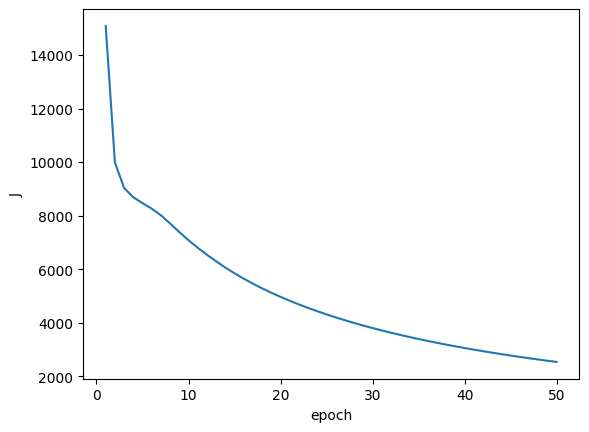

In [10]:
import time
start = time.time()
W, W_context, b, b_context, loss_history = train_glove(pairs_i, pairs_j, pairs_x, vocab_size)
print(f"training time: {time.time() - start:.0f} s, loss: {loss_history[0]:.0f} -> {loss_history[-1]:.0f}")

plt.plot(np.arange(1, len(loss_history) + 1), loss_history)
plt.xlabel("epoch")
plt.ylabel("J")
plt.show()

The objective $J$ drops from about 15,000 (random vectors) to about 2,500 after 50 epochs, and the curve is flattening out.

## Do the Vectors Satisfy the Requirements?

**Requirement: dot product plus biases is the log count.** The plot shows the fitted value against $\log X_{ij}$ (3,000 randomly chosen pairs); points on the dotted line are fitted exactly.

correlation of the prediction with log X_ij: all pairs 0.852 , pairs with X_ij >= x_max 0.97
pairs with X_ij >= x_max: 1454 , mean absolute error on them: 0.11 , on pairs with X_ij < 2: 0.5


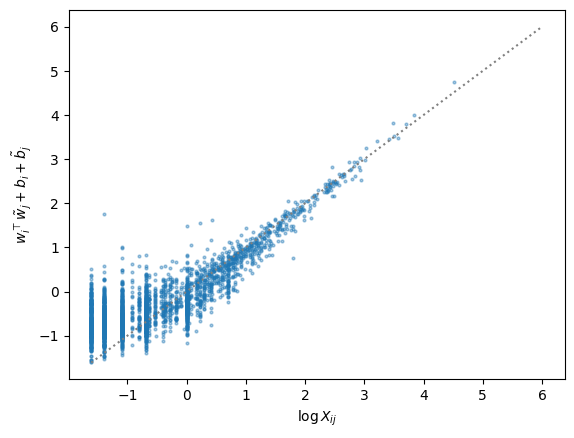

In [11]:
# fit: the dot product plus the biases against log X_ij
predicted = np.sum(W[pairs_i] * W_context[pairs_j], axis=1) + b[pairs_i] + b_context[pairs_j]
actual = np.log(pairs_x)
heavy = pairs_x >= X_MAX

print("correlation of the prediction with log X_ij: all pairs", np.corrcoef(predicted, actual)[0, 1].round(3),
      ", pairs with X_ij >= x_max", np.corrcoef(predicted[heavy], actual[heavy])[0, 1].round(3))
print("pairs with X_ij >= x_max:", int(heavy.sum()), ", mean absolute error on them:", np.abs(predicted - actual)[heavy].mean().round(2),
      ", on pairs with X_ij < 2:", np.abs(predicted - actual)[pairs_x < 2].mean().round(2))

sample = np.random.default_rng(0).choice(len(actual), 3000, replace=False)
plt.scatter(actual[sample], predicted[sample], s=4, alpha=0.4)
plt.plot([actual.min(), actual.max()], [actual.min(), actual.max()], color="gray", linestyle=":")
plt.xlabel(r"$\log X_{ij}$")
plt.ylabel(r"$w_i^\top \tilde{w}_j + b_i + \tilde{b}_j$")
plt.show()

The cloud follows the diagonal, so the model $w_i^\top \tilde{w}_j + b_i + \tilde{b}_j \approx \log X_{ij}$ can be satisfied. The correlation with $\log X_{ij}$ is 0.85 over all 74,471 pairs and 0.97 over the 1,454 pairs with $X_{ij} \ge x_{\max}$; the mean absolute error on those pairs is 0.11 on the log scale (about 12% in the counts), against 0.50 for the pairs with $X_{ij} < 2$. This is what the weight function asks for: the frequent pairs, whose counts are reliable, are reproduced precisely, and the rare, noisy ones are fitted less accurately. A fit with $D = 50$ parameters per word is not exact for all pairs, because there are far fewer parameters than entries.

**Requirement: the geometry is meaningful.** We use the sum $w_i + \tilde{w}_i$ and look at the nearest neighbours by cosine similarity.

In [12]:
vectors = W + W_context                                  # final word vectors: sum of word and context vectors
unit_vectors = vectors / np.linalg.norm(vectors, axis=1, keepdims=True)

def nearest(word, top=8):
    similarity = unit_vectors @ unit_vectors[word_to_id[word]]
    return [(vocab[j], round(float(similarity[j]), 2)) for j in np.argsort(-similarity)[1:top + 1]]

for word in ["queen", "king", "rabbit", "alice", "said", "little"]:
    print(f"{word:<7}", nearest(word))

queen   [('king', 0.77), ('dormouse', 0.77), ('the', 0.74), ('duchess', 0.72), ('gryphon', 0.67), ("'the", 0.67), ('caterpillar', 0.67), ('mock', 0.66)]
king    [('caterpillar', 0.87), ('hatter', 0.86), ('mock', 0.83), ('turtle', 0.82), ('gryphon', 0.82), ('duchess', 0.81), ('hare', 0.79), ('said', 0.78)]
rabbit  [('white', 0.94), ('cook', 0.78), ('march', 0.72), ('dodo', 0.7), ('lory', 0.69), ('turtle', 0.69), ('mock', 0.69), ('hare', 0.67)]
alice   [('thought', 0.89), ('said', 0.76), ('very', 0.72), ("'", 0.72), ('so', 0.68), ('then', 0.67), ('herself', 0.63), ('she', 0.62)]
said    [("'", 0.9), ('king', 0.78), ('alice', 0.76), ('gryphon', 0.76), ('hatter', 0.73), ("'and", 0.71), ('thought', 0.69), ('the', 0.66)]
little  [('bit', 0.77), ('door', 0.7), ('thing', 0.7), ('a', 0.65), ('house', 0.61), ('poor', 0.59), ('came', 0.57), ('large', 0.56)]


The neighbours reflect the roles of the words in the story. The nearest neighbours of "queen" are "king", "dormouse", "duchess", "gryphon" and "caterpillar": other **characters** who speak and are addressed in the same way. "king" is closest to "caterpillar", "hatter", "mock" (turtle) and "duchess", and "rabbit" to "white" (the *White Rabbit*, 0.94), "march" (hare) and "dodo". "said" has "king", "gryphon" and "hatter" as neighbours, the characters that speak. "little" is close to "bit", "thing" and "door". The vectors thus group the words by the contexts in which they are used, not by dictionary meaning: with this tiny corpus "queen" and "king" are similar because both are characters in the same scenes. Some neighbours are noise ("the" and "'the" next to "queen", since "queen" is almost always preceded by "the"), which is expected from 24,000 words. We would need a much larger corpus to see the semantic relations from the paper.

## Limitations

- **A tiny corpus.** GloVe is trained on billions of words in practice. With 24,000 words the counts of most pairs are small, the vectors of all but the most frequent words are noisy, and we cannot expect the analogies ("king - man + woman") of the paper. We changed $x_{\max}$ to 10 for this reason.
- **One vector per word.** "bank" of the river and "bank" of money share a vector, because the counts of all its occurrences are added up.
- **A dense matrix.** We store the full $V \times V$ matrix, which is only possible for a small vocabulary. Real implementations store the non-zero entries only.
- **Tokens.** We kept apostrophes in the tokens (see the bigram chapter), so quote characters appear among the neighbours.

## Summary

- The co-occurrence matrix $X$ counts how often words appear near each other; $P_{ij} = X_{ij} / X_i$ is the probability of seeing $j$ near $i$.
- The meaning of a word is better reflected in **ratios** of these probabilities than in the probabilities themselves.
- Requiring that differences of word vectors encode these ratios leads to the model $w_i^\top \tilde{w}_j + b_i + \tilde{b}_j = \log X_{ij}$; the symmetry of words and contexts gives the biases.
- The model is fitted by weighted least squares on the non-zero entries of $X$, with a weight that down-weights rare pairs and caps the frequent ones. The gradient of every term involves only four parameters.
- Compared to the [SVD](02-04-SVD.ipynb) of the count matrix, GloVe factorizes the **log** counts, ignores the zero entries and uses weights; compared with [Word2Vec](03-09-Word2Vec.ipynb) it fits the aggregated counts instead of going through the text pair by pair.

## Exercises

1. Compute $P_{ik}$ for $i = $ "queen", $j = $ "alice" and a few context words $k$ (window 5). Which context words have a ratio far from 1?
2. Use $D = 10$ and $D = 100$ instead of 50. How do the final loss and the neighbours change?
3. Set $f(x) = 1$ for all pairs (no weighting). How does the fit for rare pairs and the neighbours change?
4. Replace the final vectors $w + \\tilde{w}$ by $w$ alone. Are the neighbours different?
5. Use the window 2 instead of 5. What changes in the neighbours of "queen"?